# Squad composition and team strength — Jordan, 2015–2026

Part 3 of the project. Parts 1 and 2 are built and run from `JordanData/`; this
notebook consumes their outputs and asks the question the project exists for:

> Jordan's opponent-adjusted strength rose between 2015 and 2026. Does squad
> composition change alongside it?

**The answer cannot be causal.** Squad change, coaching change and scheduling all
move together, and with ~15 matches a year nothing here separates them. Every
number below is a description with an interval attached.

Regenerate the inputs with:

```
cd JordanData
python trajectory.py && python uncertainty.py    # strength + intervals
python fbref_fetch.py && python fbref_parse.py   # squad data
python squad_features.py && python squad_analysis.py
```

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "JordanData"))

import viz
viz.use_style()

OUT = ROOT / "outputs"
SQUAD = OUT / "squad"

strength = pd.read_csv(OUT / "jordan_strength_ci.csv", parse_dates=["date"])
feat     = pd.read_csv(SQUAD / "features_per_match.csv", parse_dates=["date"])
aligned  = pd.read_csv(SQUAD / "features_aligned.csv", parse_dates=["date"])
coverage = pd.read_csv(SQUAD / "match_coverage.csv", parse_dates=["date"])

print(f"strength trace   {len(strength):>4} reference dates")
print(f"per-match feats  {len(feat):>4} matches")
print(f"aligned          {len(aligned):>4} periods")
print(f"spine coverage   {len(coverage):>4} matches")

strength trace     30 reference dates
per-match feats   164 matches
aligned            30 periods
spine coverage    488 matches


## 1. What the strength model says

The trace is refit every six months using only matches before that date, so each
point is something you could have computed on the day. The band is a 95%
percentile interval from 500 bootstrap draws.

findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


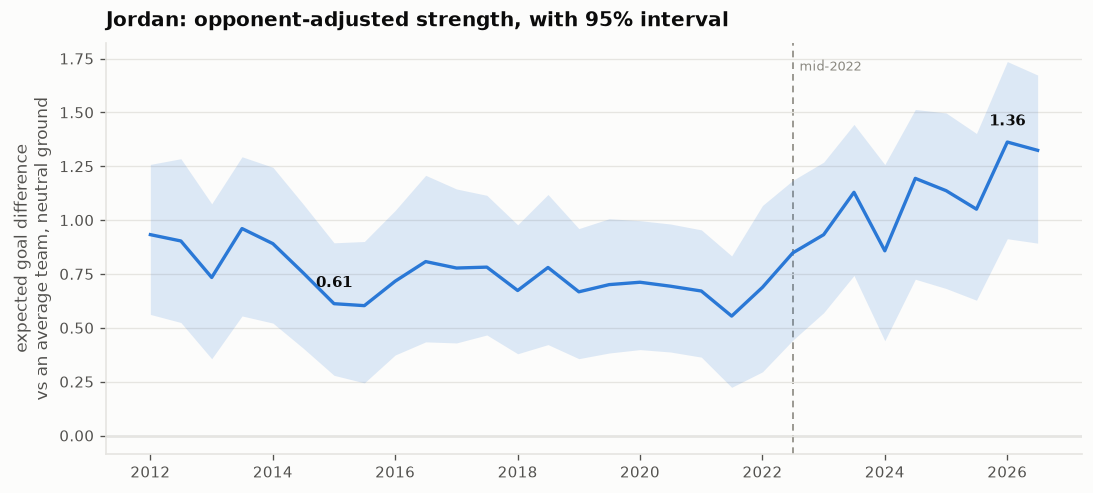

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))

ax.fill_between(strength.date, strength.strength_lo, strength.strength_hi,
                color=viz.BLUE, alpha=0.15, linewidth=0)
ax.plot(strength.date, strength.strength, color=viz.BLUE)
viz.mark_split(ax)
viz.despine(ax)

ax.set_title("Jordan: opponent-adjusted strength, with 95% interval")
ax.set_ylabel("expected goal difference\nvs an average team, neutral ground")
ax.axhline(0, color=viz.INK_MUTED, linewidth=0.8, zorder=0)

for when in ("2015-01-01", "2026-01-01"):
    row = strength.loc[strength.date == when].iloc[0]
    ax.annotate(f"{row.strength:.2f}", xy=(row.date, row.strength),
                xytext=(0, 10), textcoords="offset points",
                ha="center", fontsize=9, color=viz.INK, fontweight="semibold")
plt.show()

The rise is real: **+0.717, 95% CI [+0.203, +1.220]** from 2015 to 2026.

The interval also settles what *cannot* be said. 2026 is the highest point
estimate but is not separable from its neighbours (2026 vs 2023: +0.411,
CI [−0.031, +0.867]). "At the top of the range" is supportable; "the peak" is not.

## 2. The divergence that motivates the project

2026 is simultaneously Jordan's worst raw goal difference and its highest strength
estimate. Both are correct — the 2026 opponents were Argentina, Austria, Algeria,
Switzerland and Colombia.

Two measures on different scales, so they get **two panels sharing an x-axis**,
never two y-axes on one plot.

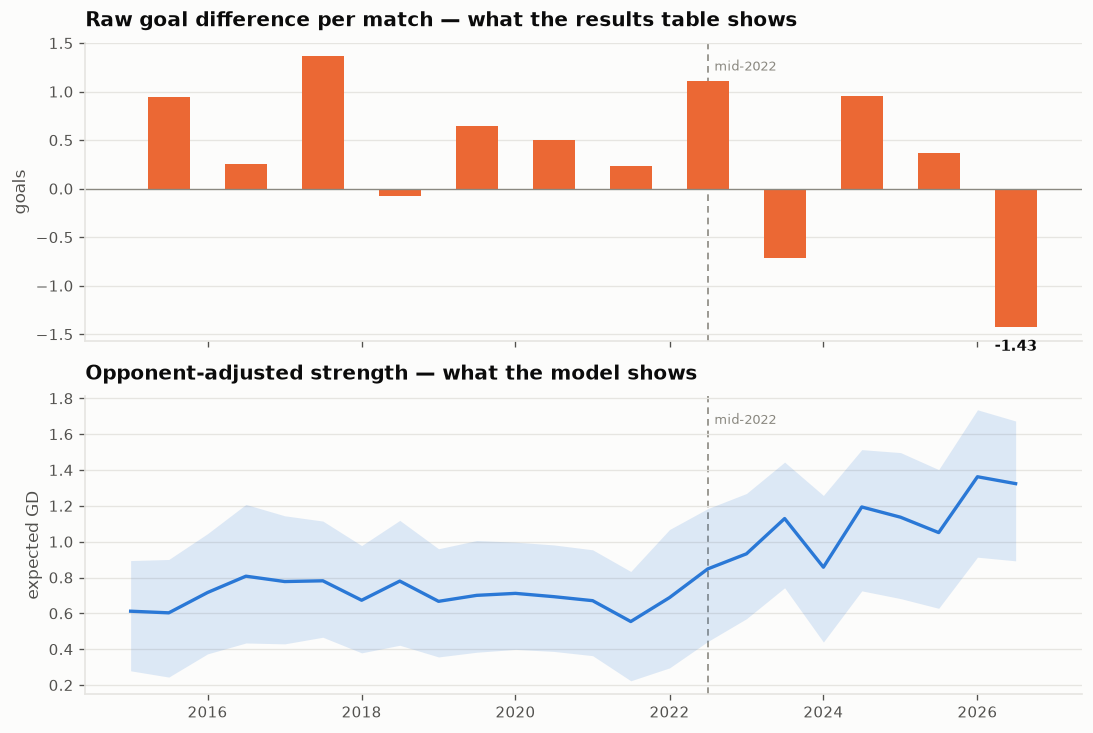

In [3]:
spine = coverage.copy()
spine["year"] = spine.date.dt.year
spine["gd"] = spine.gf - spine.ga
raw = (spine[spine.year.between(2015, 2026)]
       .groupby("year").gd.mean().reset_index())
raw["date"] = pd.to_datetime(raw.year.astype(str) + "-07-01")

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)

ax = axes[0]
ax.bar(raw.date, raw.gd, width=200, color=viz.ORANGE, align="center", zorder=2)
ax.axhline(0, color=viz.INK_MUTED, linewidth=0.8)
viz.despine(ax); viz.mark_split(ax)
ax.set_title("Raw goal difference per match — what the results table shows")
ax.set_ylabel("goals")

worst = raw.loc[raw.gd.idxmin()]
ax.annotate(f"{worst.gd:+.2f}", xy=(worst.date, worst.gd),
            xytext=(0, -14), textcoords="offset points",
            ha="center", fontsize=9, color=viz.INK, fontweight="semibold")

ax = axes[1]
s = strength[strength.date >= "2015-01-01"]
ax.fill_between(s.date, s.strength_lo, s.strength_hi,
                color=viz.BLUE, alpha=0.15, linewidth=0)
ax.plot(s.date, s.strength, color=viz.BLUE)
viz.despine(ax); viz.mark_split(ax)
ax.set_title("Opponent-adjusted strength — what the model shows")
ax.set_ylabel("expected GD")
plt.show()

## 3. Coverage: what the squad data actually rests on

Before any composition measure is quoted, this is the base. 126 of 156 matches
since 2015 yield a full XI (81%). The 30 gaps are three different problems:

| n | reason |
|---|---|
| 15 | competition not tracked by FBref — Arab Cup (10), WAFF (3), invitational (2) |
| 10 | a friendly in a tracked competition that FBref simply doesn't hold |
| 5 | FBref report exists but carries no lineup |

The first group matters most for interpretation: those are competitive fixtures,
and Arab Cup and WAFF are exactly where a second-string XI would appear — so
**turnover measured from this data is biased downward**, and unevenly across
years. 2025 is the worst-covered year, losing the whole December Arab Cup.

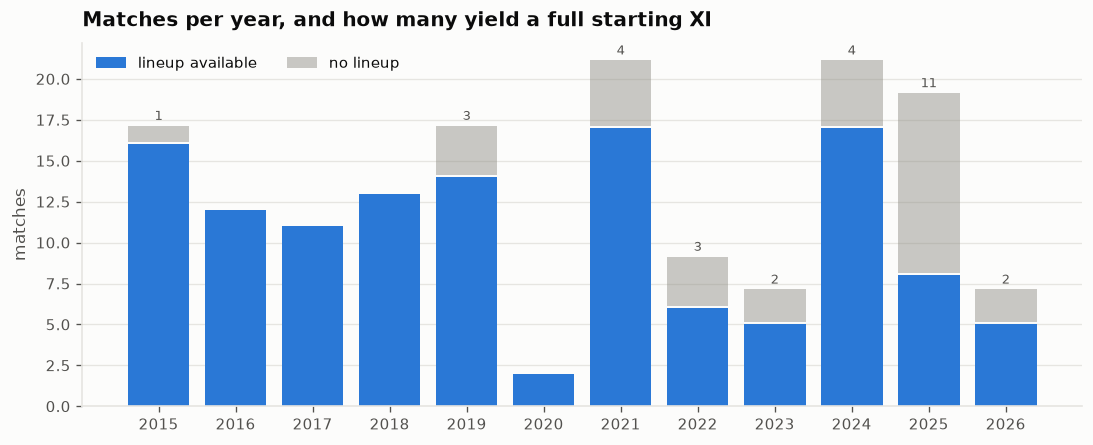

since 2015: 126 of 156 matches (81%) have a full XI


In [4]:
cov = coverage[coverage.date >= "2015-01-01"].copy()
cov["year"] = cov.date.dt.year
tab = (cov.groupby("year")
          .agg(total=("has_xi", "size"), with_xi=("has_xi", "sum"))
          .assign(missing=lambda d: d.total - d.with_xi))

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(tab.index, tab.with_xi, color=viz.BLUE, label="lineup available", zorder=2)
ax.bar(tab.index, tab.missing, bottom=tab.with_xi + 0.15,
       color=viz.INK_MUTED, alpha=0.45, label="no lineup", zorder=2)
viz.despine(ax)
ax.set_title("Matches per year, and how many yield a full starting XI")
ax.set_ylabel("matches")
ax.set_xticks(tab.index)
ax.legend(loc="upper left", ncols=2)

for yr, row in tab.iterrows():
    if row.missing:
        ax.annotate(f"{int(row.missing)}", xy=(yr, row.total + 0.5),
                    ha="center", fontsize=8, color=viz.INK_2)
plt.show()

print(f"since 2015: {tab.with_xi.sum()} of {tab.total.sum()} matches "
      f"({tab.with_xi.sum() / tab.total.sum():.0%}) have a full XI")

## 4. Composition over time

Four measures, all built from lineups and minutes only — never from advanced
stats, which change provider near the treatment date and don't exist for
friendlies in any era.

Each point is a six-month period, matching the strength trace's reference dates.

findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


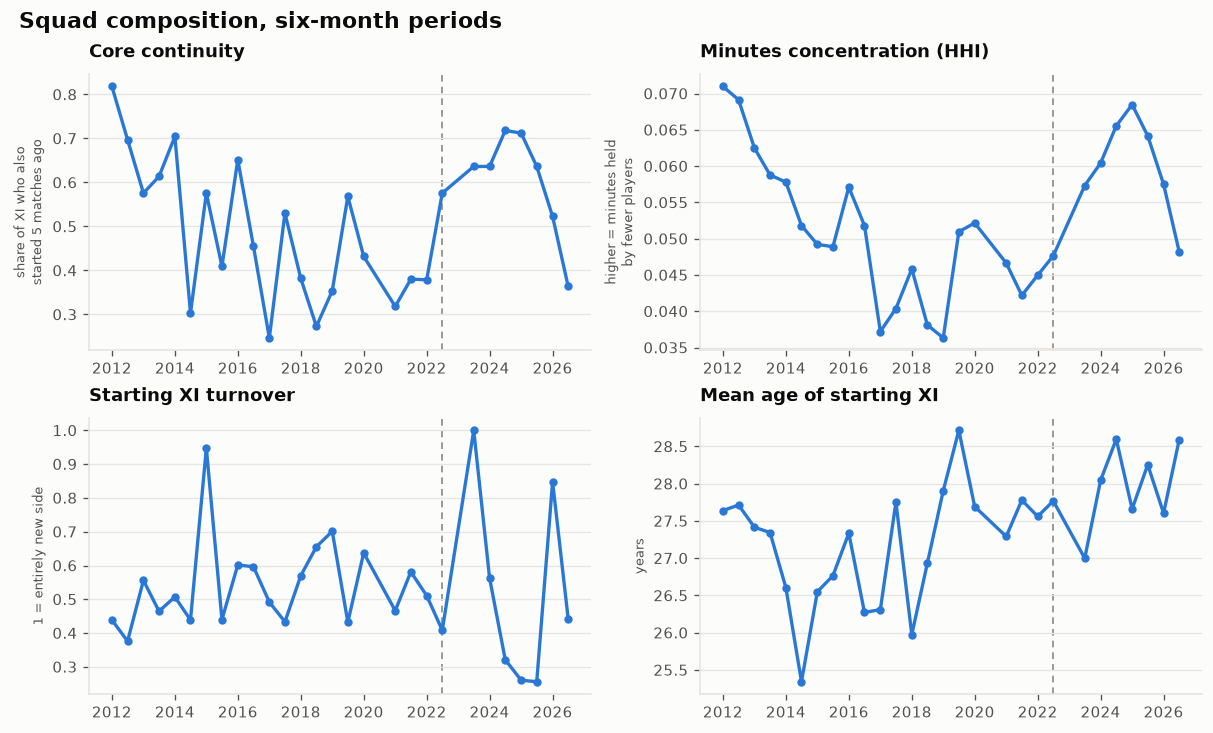

In [5]:
panels = [
    ("core_continuity", "Core continuity", "share of XI who also\nstarted 5 matches ago"),
    ("hhi_minutes",     "Minutes concentration (HHI)", "higher = minutes held\nby fewer players"),
    ("turnover",        "Starting XI turnover", "1 = entirely new side"),
    ("age_mean",        "Mean age of starting XI", "years"),
]

fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, (col, title, ylab) in zip(axes.ravel(), panels):
    d = aligned.dropna(subset=[col])
    ax.plot(d.date, d[col], color=viz.BLUE, marker="o", markersize=4)
    viz.mark_split(ax, label="")
    viz.despine(ax)
    ax.set_title(title, fontsize=11)
    ax.set_ylabel(ylab, fontsize=8)
fig.suptitle("Squad composition, six-month periods", fontsize=13,
             fontweight="semibold", x=0.01, ha="left", color=viz.INK)
plt.show()

## 5. Does composition shift across the treatment date?

The split is 2022-07-01, fixed in `CLAUDE.md` on the basis of results before any
of this was computed — not chosen after seeing these series.

Bootstrapped over six-month blocks rather than over matches: consecutive matches
share players almost by definition, so treating them as independent would give
intervals several times too narrow.

In [6]:
pp = pd.read_csv(SQUAD / "analysis_prepost.csv")
cc = pd.read_csv(SQUAD / "analysis_correlation.csv")

label = {"core_continuity": "Core continuity", "hhi_minutes": "Minutes concentration",
         "turnover": "XI turnover", "age_mean": "Mean age (years)",
         "n_debuts": "Debuts per match"}
pp["name"] = pp.feature.map(label)
pp[["name", "pre", "post", "diff", "lo", "hi", "diff_sd", "crosses_zero"]].round(3)

,name,pre,post,diff,lo,hi,diff_sd,crosses_zero
0,XI turnover,0.546,0.479,-0.067,-0.236,0.190,-0.269,True
1,Core continuity,0.461,0.636,0.175,0.035,0.259,0.933,False
2,Mean age (years),27.292,28.174,0.881,0.303,1.332,0.759,False
3,Minutes concentration,0.049,0.061,0.012,0.005,0.018,1.284,False
4,Debuts per match,0.783,0.400,-0.383,-0.841,0.226,-0.270,True


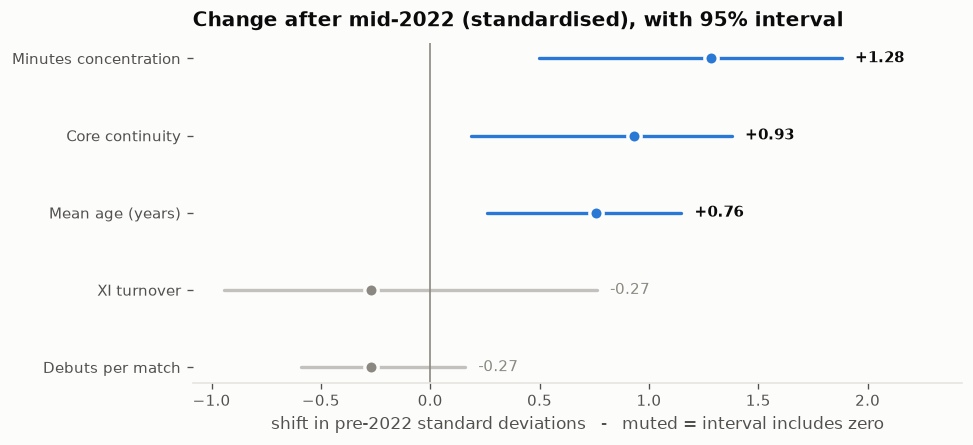

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.6))
d = pp.sort_values("diff_sd").reset_index(drop=True)

for i, r in d.iterrows():
    solid = not r.crosses_zero
    colour = viz.BLUE if solid else viz.INK_MUTED
    ax.plot([r.lo_sd, r.hi_sd], [i, i], color=colour, linewidth=2,
            alpha=1.0 if solid else 0.5, solid_capstyle="round", zorder=2)
    ax.plot([r.diff_sd], [i], "o", color=colour, markersize=8, zorder=3,
            markeredgecolor=viz.SURFACE, markeredgewidth=2)
    ax.annotate(f"{r.diff_sd:+.2f}", xy=(r.hi_sd, i), xytext=(8, 0),
                textcoords="offset points", va="center", fontsize=9,
                color=viz.INK if solid else viz.INK_MUTED,
                fontweight="semibold" if solid else "normal")

ax.axvline(0, color=viz.INK_MUTED, linewidth=1.0, zorder=1)
ax.set_yticks(np.arange(len(d)), d.name)
viz.despine(ax, keep=("bottom",))
ax.grid(axis="y", visible=False)
ax.set_xlim(right=d.hi_sd.max() + 0.55)
ax.set_title("Change after mid-2022 (standardised), with 95% interval")
ax.set_xlabel("shift in pre-2022 standard deviations   -   muted = interval includes zero")
plt.show()

Three measures move with intervals clear of zero: the squad becomes **more
continuous**, **older**, and its **minutes more concentrated**. Turnover and debut
count point the same way but their intervals include zero.

The chart is standardised because the raw units are incommensurable — years, an
HHI, a 0-1 share. On a raw axis the age change (+0.88 years) swamps everything
and minutes concentration (+0.012) renders as an invisible dot, which inverts the
actual finding: in standard-deviation terms **minutes concentration is the
largest effect of the five**.

Turnover is also the measure most damaged by the coverage hole — the missing Arab
Cup and WAFF fixtures are precisely where a second-string XI would appear.

In [8]:
cc["name"] = cc.feature.map(label)
cc[["name", "spearman", "lo", "hi", "crosses_zero", "n"]].round(3)

,name,spearman,lo,hi,crosses_zero,n
0,XI turnover,-0.324,-0.573,-0.032,False,28
1,Core continuity,0.511,0.159,0.837,False,28
2,Mean age (years),0.275,-0.287,0.589,True,28
3,Minutes concentration,0.609,0.219,0.841,False,28
4,Debuts per match,-0.262,-0.665,0.048,True,28


## 6. What this does and does not establish

**Supported.** Post-2022 Jordan fields a more settled, older squad with minutes
concentrated in fewer players. Continuity and minutes concentration also co-move
with contemporaneous strength.

**Not established.** That any of this is *Jordan's* pattern. There is no placebo
here. Iraq, Palestine, Oman and Bahrain would need the same pipeline run over
their squads before distinctiveness is claimable — and this project has already
watched one promising per-team effect collapse once the cross-team spread was
measured and turned out to be indistinguishable from noise.

**Ruled out by design.** Any causal reading. Two slowly-trending series correlate
because they trend. Composition, coaching and fixture difficulty all moved
together over this window and nothing here separates them.

One-line summary: *Jordan's squad settled as its strength rose, and we cannot
presently say whether that is Jordan-specific or what every improving side looks
like.*

### Next
1. Run the placebo (Iraq, Palestine, Oman, Bahrain) — the one thing that would
   upgrade section 5 from description to evidence.
2. Hand-enter the 10 Arab Cup matches; schema and `source` column are ready.